# Warehouse operations analysis: walkthrough

**Question:** *Where does the warehouse lose time, what is the real root cause, and which operational change would reduce delays most?*

This notebook walks through the analysis one step at a time using the `warehouse` package. It does not contain any analysis code of its own: every number comes from the same functions that `run_analysis.py` uses, so the notebook, the report and the README always agree.

> The data is **synthetic** (generated in Excel), not real company data. Because the rules that generated it are known, we can check whether the methods recover them.

In [1]:
import sys
from pathlib import Path

# Make the project root importable when the notebook is opened from notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "warehouse").is_dir())
sys.path.insert(0, str(ROOT))

import pandas as pd
from warehouse import config, data, metrics, stats_tests, model, scenarios, report

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
print(f"Delay threshold: {config.DELAY_THRESHOLD:g} min | seed: {config.RANDOM_SEED} | bootstrap: {config.BOOTSTRAP_ITERATIONS}")

Delay threshold: 15 min | seed: 42 | bootstrap: 500


## Step 1: Validate

Before calculating anything, check the data. If a single check fails the analysis stops, because every later number would be untrustworthy.

In [2]:
raw = data.load_data(config.RAW_DATA)
validation = data.validate_data(raw)
data.assert_valid(validation)   # raises DataValidationError if anything failed
validation

,check,issues_found,result
0,Missing values (cells),0,PASS
1,Duplicate rows,0,PASS
2,Duplicate Order Ids,0,PASS
3,Pick or Pack time <= 0,0,PASS
4,Items outside 1-10,0,PASS
5,Dates outside August 2026 or unreadable,0,PASS
6,Processing != Pick + Pack (tolerance 0.01),0,PASS
7,Unexpected Zone labels,0,PASS
8,Unexpected Shift labels,0,PASS
9,Unexpected Worker Experience labels,0,PASS


In [3]:
df = data.clean_data(raw, threshold=config.DELAY_THRESHOLD)
df[["Order Id", "Date", "Zone", "Shift", "Worker Experience", "Processing Time", "Delayed Flag", "Workload Band"]].head()

,Order Id,Date,Zone,Shift,Worker Experience,Processing Time,Delayed Flag,Workload Band
0,O0001,2026-08-11,C,Evening,Experienced,14.4,0,130+
1,O0002,2026-08-29,B,Evening,Experienced,10.3,0,130+
2,O0003,2026-08-25,A,Evening,Experienced,12.2,0,100-129
3,O0004,2026-08-11,C,Afternoon,Experienced,9.8,0,100-129
4,O0005,2026-08-22,C,Morning,Experienced,16.2,1,<100


## Step 2: Describe

Two rates, two questions:

* **delay rate**: delayed orders in the group ÷ orders in the group. *How likely is an order from this group to be late?*
* **share of all delays**: delayed orders in the group ÷ all delayed orders. *How much of the whole problem sits in this group?*

In [4]:
k = metrics.kpis(df)
print(f"{k['orders']:,} orders, {k['delayed_orders']:,} delayed ({report.pct(k['delay_rate'])}), "
      f"mean {k['mean_processing']:.2f} min, 90th percentile {k['p90_processing']:.1f} min")
by_zone = metrics.summarise_by(df, "Zone")
by_zone

10,000 orders, 1,375 delayed (13.8%), mean 12.15 min, 90th percentile 15.6 min


,Zone,orders,share_of_orders,delayed_orders,delay_rate,share_of_delays,mean_processing,median_processing,p90_processing,error_rate
0,A,2473,0.247,77,0.031,0.056,10.732,10.6,13.6,0.035
1,B,2527,0.253,217,0.086,0.158,11.858,11.7,14.8,0.039
2,C,2528,0.253,854,0.338,0.621,14.097,13.9,17.4,0.077
3,D,2472,0.247,227,0.092,0.165,11.866,11.7,14.9,0.036


The same numbers by hand for Zone C, to show exactly what `summarise_by` does:

In [5]:
zone_c = df[df["Zone"] == "C"]
print("Zone C delay rate      =", zone_c["Delayed Flag"].sum(), "/", len(zone_c), "=",
      report.pct(zone_c["Delayed Flag"].mean()))
print("Zone C share of delays =", zone_c["Delayed Flag"].sum(), "/", df["Delayed Flag"].sum(), "=",
      report.pct(zone_c["Delayed Flag"].sum() / df["Delayed Flag"].sum()))

Zone C delay rate      = 854 / 2528 = 33.8%
Zone C share of delays = 854 / 1375 = 62.1%


In [6]:
metrics.summarise_by(df, "Shift")

,Shift,orders,share_of_orders,delayed_orders,delay_rate,share_of_delays,mean_processing,median_processing,p90_processing,error_rate
0,Afternoon,2945,0.294,294,0.100,0.214,11.701,11.5,15.0,0.042
1,Evening,4044,0.404,798,0.197,0.580,12.810,12.6,16.4,0.055
2,Morning,3011,0.301,283,0.094,0.206,11.695,11.5,14.9,0.039


In [7]:
metrics.summarise_by(df, "Workload Band")

,Workload Band,orders,share_of_orders,delayed_orders,delay_rate,share_of_delays,mean_processing,median_processing,p90_processing,error_rate
0,<100,3437,0.344,343,0.100,0.249,11.727,11.5,15.0,0.04
1,100-129,4354,0.435,585,0.134,0.425,12.136,11.9,15.6,0.05
2,130+,2209,0.221,447,0.202,0.325,12.824,12.6,16.5,0.05


Busier shifts look worse. Is workload the cause? Keep that question in mind: Step 4 answers it.

## Step 3: Root cause

Split each zone by worker experience, and add Wilson 95% confidence intervals to the delay rates.

In [8]:
ze = stats_tests.add_wilson_ci(metrics.summarise_by(df, ["Zone", "Worker Experience"]))
ze[["Zone", "Worker Experience", "orders", "delay_rate", "delay_rate_ci_low", "delay_rate_ci_high", "share_of_delays"]]

,Zone,Worker Experience,orders,delay_rate,delay_rate_ci_low,delay_rate_ci_high,share_of_delays
0,A,Experienced,1712,0.002,9.090e-04,0.006,0.003
1,A,New,761,0.096,7.699e-02,0.119,0.053
2,B,Experienced,1779,0.022,1.656e-02,0.030,0.029
3,B,New,748,0.237,2.076e-01,0.268,0.129
4,C,Experienced,1787,0.208,1.894e-01,0.227,0.270
5,C,New,741,0.652,6.168e-01,0.685,0.351
6,D,Experienced,1712,0.018,1.230e-02,0.025,0.022
7,D,New,760,0.259,2.293e-01,0.292,0.143


Are New workers concentrated in Zone C? If they were, that alone could explain Zone C. The crosstab and chi-square test say no:

In [9]:
spread = pd.crosstab(df["Zone"], df["Worker Experience"], normalize="index")
display(spread)
tests = stats_tests.run_test_suite(df)
tests[["test", "method", "p_value", "p_bonferroni", "effect_size", "effect_measure", "significant_after_correction"]]

Worker Experience,Experienced,New
Zone,,
A,0.692,0.308
B,0.704,0.296
C,0.707,0.293
D,0.693,0.307


,test,method,p_value,p_bonferroni,effect_size,effect_measure,significant_after_correction
0,Delayed vs Zone,Chi-square,5.011e-258,3.507e-257,0.345,Cramer's V,True
1,Delayed vs Experience (Zone C),Chi-square,1.724e-102,1.207e-101,0.428,Cramer's V,True
2,Worker Experience vs Zone,Chi-square,5.589e-01,1.000e+00,0.014,Cramer's V,False
3,Processing time: Zone C vs other zones,Welch t-test,0.000e+00,0.000e+00,1.108,Cohen's d,True
4,Processing time: Zone C vs other zones,Mann-Whitney U,0.000e+00,0.000e+00,0.782,P(a > b),True
5,Processing time: New vs Experienced (Zone C),Welch t-test,1.921e-139,1.345e-138,1.282,Cohen's d,True
6,Processing time: New vs Experienced (Zone C),Mann-Whitney U,5.643e-136,3.950e-135,0.813,P(a > b),True


In [10]:
new_c = ze[(ze["Zone"] == "C") & (ze["Worker Experience"] == "New")].iloc[0]
print(f"New workers in Zone C: {report.pct(new_c['share_of_orders'])} of all orders, "
      f"{report.pct(new_c['share_of_delays'])} of ALL delayed orders.")

New workers in Zone C: 7.4% of all orders, 35.1% of ALL delayed orders.


## Step 4: Separate the effects

### 4a-b. Pick and pack time models (non-linear least squares)

`pick = (base_zone + k × items) × m_evening^[Evening] × m_new^[New]` and `pack = (a + b × items) × p_new^[New]`.

The bootstrap refits both models on resampled orders to get 95% confidence intervals.

In [11]:
estimates = model.fit_time_models(df)
draws = model.bootstrap_time_models(df, estimates, iterations=config.BOOTSTRAP_ITERATIONS, seed=config.RANDOM_SEED)
time_params = model.parameter_table(estimates, draws)
print(model.time_model_fit_stats(df, estimates))
time_params

{'pick_r2': 0.7985196334329833, 'pick_mae': 0.7862847309536833, 'pack_r2': 0.629310829329726, 'pack_mae': 0.4297220317233656}


,parameter,estimate,ci_low,ci_high
0,base_A,4.049,4.005,4.088
1,base_B,5.035,4.987,5.078
2,base_C,7.018,6.965,7.066
3,base_D,5.013,4.965,5.060
4,k,0.293,0.288,0.299
5,m_evening,1.156,1.150,1.161
6,m_new,1.247,1.241,1.254
7,pack_a,3.010,2.992,3.027
8,pack_b,0.197,0.194,0.200
9,p_new,1.150,1.144,1.155


### 4c. Error model (linear probability model, HC3 robust errors) and the logistic robustness check

Coefficients are in **percentage points** of error probability.

In [12]:
lpm = model.coef_table(model.fit_error_model(df))
lpm.merge(model.fit_error_logit(df), on="term", how="left")

,term,estimate,ci_low,ci_high,p_value,logit_ame,logit_ci_low,logit_ci_high,logit_p_value
0,Intercept,0.959,-0.286,2.203,1.310e-01,NaN,NaN,NaN,NaN
1,zone_B,0.387,-0.655,1.429,4.669e-01,0.493,-0.805,1.791,4.567e-01
2,zone_C,4.209,2.947,5.472,6.414e-11,3.710,2.535,4.885,6.044e-10
3,zone_D,0.088,-0.936,1.112,8.661e-01,0.120,-1.211,1.450,8.598e-01
4,shift_Afternoon,0.312,-0.689,1.314,5.411e-01,0.329,-0.808,1.465,5.709e-01
5,shift_Evening,1.911,0.178,3.645,3.071e-02,1.900,0.193,3.607,2.915e-02
6,experience_New,2.507,1.525,3.489,5.663e-07,2.332,1.479,3.185,8.391e-08
7,category_Electronics,1.219,0.233,2.206,1.539e-02,1.287,0.241,2.333,1.589e-02
8,category_Home,1.154,0.171,2.136,2.138e-02,1.235,0.194,2.276,2.004e-02
9,priority_Priority,0.400,-0.558,1.359,4.132e-01,0.407,-0.515,1.329,3.867e-01


### 4d. Workload confounding

If workload truly caused delays, its effect should survive once we compare shifts of the same type. Evening shifts are both the busiest and the slowest, so a model with workload alone gives workload the credit for the evening effect.

In [13]:
confounding, corr = model.workload_confounding(df)
print(f"Correlation between Evening and Orders in Shift: {corr:.2f}")
confounding

Correlation between Evening and Orders in Shift: 0.86


,model,term,estimate,ci_low,ci_high,p_value
0,Shift only,shift_Evening,10.334,8.724,11.944,2.737e-36
1,Workload only,workload_10,2.075,1.719,2.432,3.810e-30
2,Shift + workload,shift_Evening,11.510,8.722,14.298,5.934e-16
3,Shift + workload,workload_10,-0.352,-1.028,0.324,3.072e-01


### 4e. Validation against the known true process

The centrepiece. For every parameter: the true value used to generate the data, the estimate, the 95% CI and whether the CI contains the truth. "No effect" rows should include zero; with many such checks, about 1 in 20 will look significant by chance alone.

In [14]:
residual = model.coef_table(model.pick_residual_check(df, estimates))
validation_table = model.validation_table(time_params, lpm, residual)
validation_table

,section,parameter,units,true_value,estimate,ci_low,ci_high,p_value,check_type,contains_truth,excludes_zero
0,Pick time model,base_A,minutes,4.00,4.049,4.005,4.088,NaN,built-in effect,False,True
1,Pick time model,base_B,minutes,5.00,5.035,4.987,5.078,NaN,built-in effect,True,True
2,Pick time model,base_C,minutes,7.00,7.018,6.965,7.066,NaN,built-in effect,True,True
3,Pick time model,base_D,minutes,5.00,5.013,4.965,5.060,NaN,built-in effect,True,True
4,Pick time model,k,minutes per item,0.30,0.293,0.288,0.299,NaN,built-in effect,False,True
5,Pick time model,m_evening,multiplier (x),1.15,1.156,1.150,1.161,NaN,built-in effect,True,True
6,Pick time model,m_new,multiplier (x),1.25,1.247,1.241,1.254,NaN,built-in effect,True,True
7,Pack time model,p_new,multiplier (x),1.15,1.150,1.144,1.155,NaN,built-in effect,True,True
8,Error model (LPM),Baseline error rate (reference group*),percentage points,2.00,0.959,-0.286,2.203,1.310e-01,built-in effect,True,False
9,Error model (LPM),Zone B,percentage points,0.00,0.387,-0.655,1.429,4.669e-01,no effect,True,False


In [15]:
results_for_text = {"validation": validation_table, "kpis": k}
print(report.validation_commentary(results_for_text))

- 10 of 12 built-in parameters have a 95% CI containing the true value. Every time-model parameter is within 2.2% of its true value; error-model effects are within 1.04 percentage points (errors are rare, so these estimates are much noisier).
- Missed: base_A (4.049 vs 4), k (0.293 vs 0.3). The estimates are close in practical terms, but the bootstrap CI only reflects sampling noise. It cannot capture details of how Excel generated the data (for example rounding to 0.1 min or the exact shape of the noise), so a very narrow CI can sit just beside the truth.
- 8 of 11 'no effect' checks correctly include zero.
- **False positives:** Category Electronics in 'Error model (LPM)' (+1.22 percentage points, p = 0.015), Category Home in 'Error model (LPM)' (+1.15 percentage points, p = 0.021), Priority order (vs Standard) in 'Pick time: no-effect checks' (-0.82% of pick time, p = 0.002). With 11 no-effect checks at the 5% level, about 0.6 would be expected to look 'significant' by chance alone.

### 4f. Out-of-sample check

Fit on a random 80% of orders and score on the unseen 20%. A naive 'zone average' predictor is shown for comparison.

In [16]:
model.out_of_sample_check(df, seed=config.RANDOM_SEED)

,sample,orders,model_mae,model_r2,zone_average_mae,zone_average_r2
0,train (80%),8046,0.790,0.799,1.348,0.346
1,test (20%),1954,0.771,0.797,1.322,0.346


## Step 5: Scenario simulation

Each scenario changes order times using the **estimated** multipliers, then recomputes the delay flag with the same threshold. No queues are modelled: the data has no arrival times or staffing levels.

In [17]:
effects = scenarios.effects_from(estimates)
table = scenarios.run_scenarios(df, effects, config.DELAY_THRESHOLD, config.RANDOM_SEED)
table = table.merge(scenarios.scenario_uncertainty(df, draws, config.DELAY_THRESHOLD, config.RANDOM_SEED), on="scenario")
table[["scenario", "description", "delay_rate", "zone_c_delay_rate", "delayed_avoided", "avoided_low", "avoided_high",
       "pick_minutes_change", "orders_affected", "avoided_per_100_affected"]]

,scenario,description,delay_rate,zone_c_delay_rate,delayed_avoided,avoided_low,avoided_high,pick_minutes_change,orders_affected,avoided_per_100_affected
0,S0,Baseline (observed),0.138,0.338,0,0.000,0.00,0.000,0,NaN
1,S1,Support New workers in Zone C,0.101,0.195,361,352.000,370.00,-1669.319,741,48.718
2,S2,Re-roster: swap New workers out of Zone C,0.115,0.195,225,199.475,241.05,-436.080,1482,15.182
3,S3 (0.5 min),Zone C layout: base pick -0.5 min,0.119,0.265,185,185.000,185.00,-1440.033,2528,7.318
4,S3 (1 min),Zone C layout: base pick -1 min,0.101,0.195,362,362.000,362.00,-2880.066,2528,14.320
5,S3 (1.5 min),Zone C layout: base pick -1.5 min,0.087,0.140,500,500.000,500.00,-4320.099,2528,19.778
6,S3 (2 min),Zone C layout: base pick -2 min,0.076,0.096,612,612.000,622.00,-5760.132,2528,24.209
7,S4 (S1 + S3 1 min),Combined S1 + layout,0.073,0.083,644,642.000,647.00,-4549.384,2528,25.475


Ranking by delays avoided per 100 orders whose handling changes (the disruption measure), and the same ranking at other thresholds:

In [18]:
ranking = scenarios.rank_scenarios(table)
display(ranking[["rank", "scenario", "delayed_avoided", "avoided_per_100_affected"]])
sens = scenarios.threshold_sensitivity(df, effects, seed=config.RANDOM_SEED)
sens[sens["rank"] <= 2]

,rank,scenario,delayed_avoided,avoided_per_100_affected
0,1,S1,361,48.718
1,2,S4 (S1 + S3 1 min),644,25.475
2,3,S3 (2 min),612,24.209
3,4,S3 (1.5 min),500,19.778
4,5,S2,225,15.182
5,6,S3 (1 min),362,14.320
6,7,S3 (0.5 min),185,7.318


,threshold,scenario,delayed_avoided,avoided_per_100_affected,rank
0,12.0,S3 (2 min),842,33.307,1
1,12.0,S4 (S1 + S3 1 min),714,28.244,2
7,15.0,S1,361,48.718,1
8,15.0,S4 (S1 + S3 1 min),644,25.475,2
14,18.0,S1,136,18.354,1
15,18.0,S2,117,7.895,2


### Trial design

How many New-worker Zone C orders would a trial need to detect the expected improvement (two-proportion test, 80% power, alpha 0.05)?

In [19]:
scenarios.trial_design(df, effects, config.DELAY_THRESHOLD)

,case,baseline_rate,target_rate,orders_per_group,orders_total,new_zone_c_orders_per_day,days_needed,icc,avg_cluster_size,deff,clusters_per_day,orders_per_group_clustered,clusters_per_arm,days_needed_clustered
0,Expected improvement (to observed Experienced ...,0.652,0.208,19,38,23.903,2,0.06,7.968,1.418,3.0,27,4,3
1,Half the expected improvement,0.652,0.430,78,156,23.903,7,0.06,7.968,1.418,3.0,111,14,10


## Charts

The charts are drawn by `run_analysis.py` from the tables above and saved in `outputs/charts/`.

01_delay_rate_by_zone.png


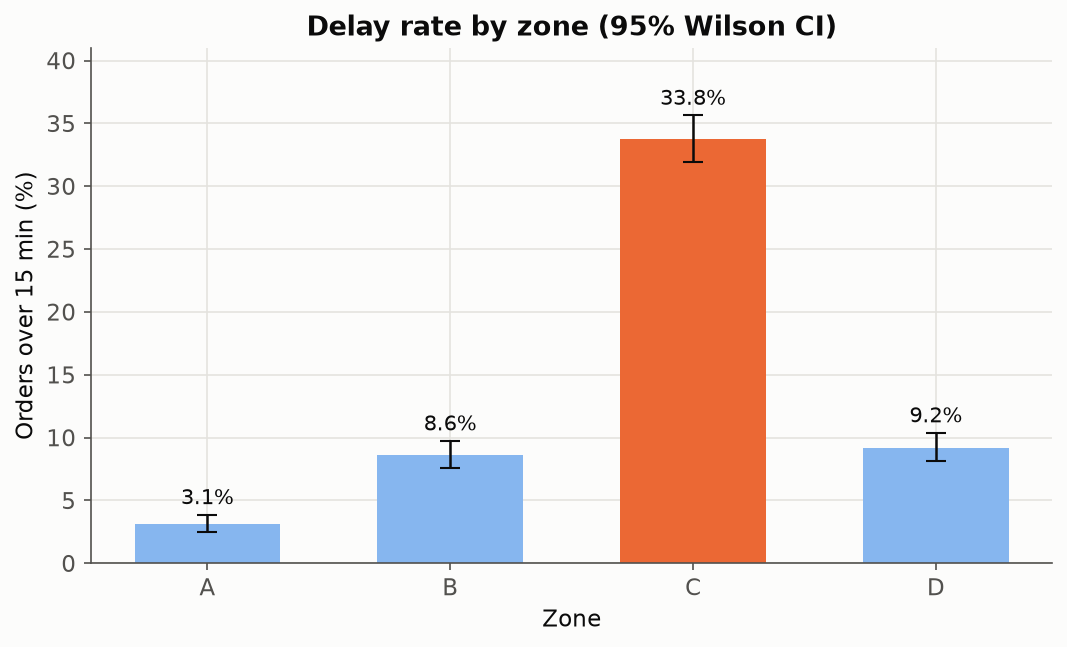

02_share_orders_vs_delays.png


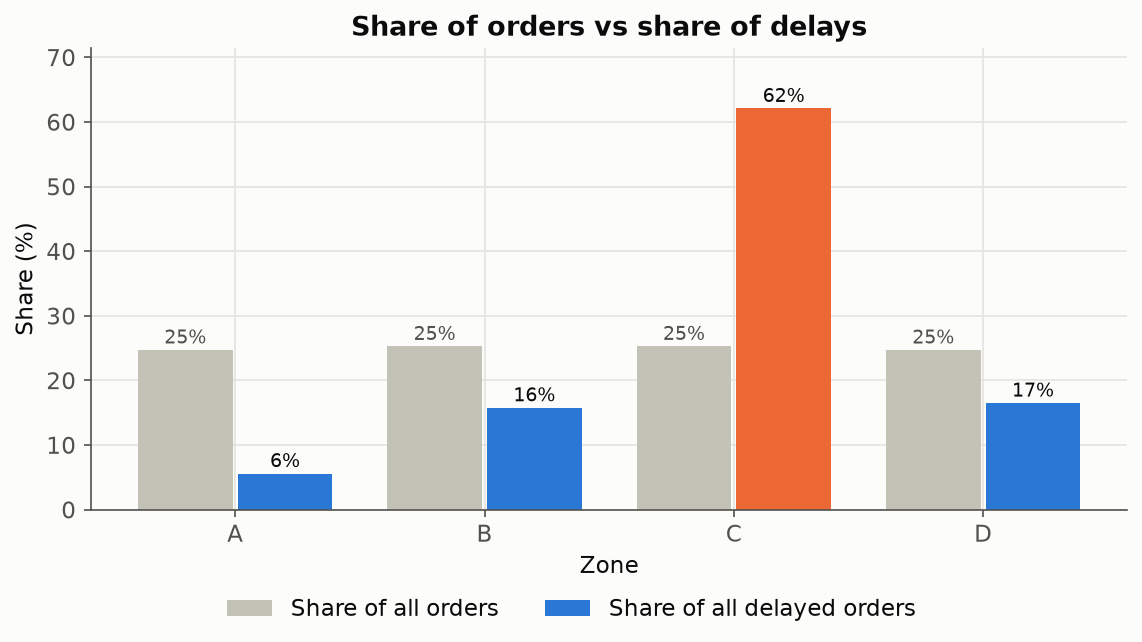

03_zone_experience_heatmap.png


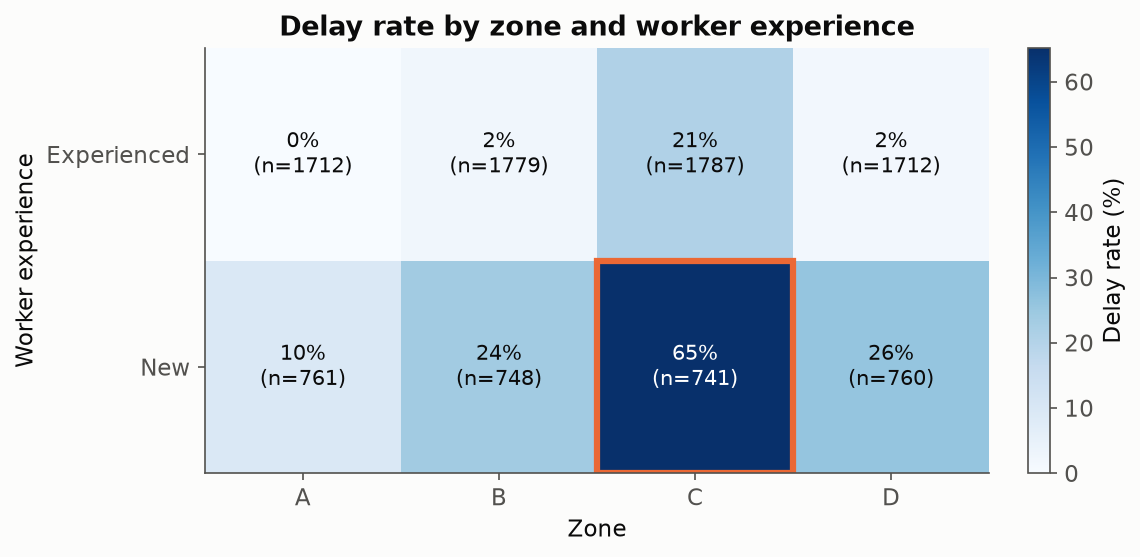

04_processing_time_by_zone.png


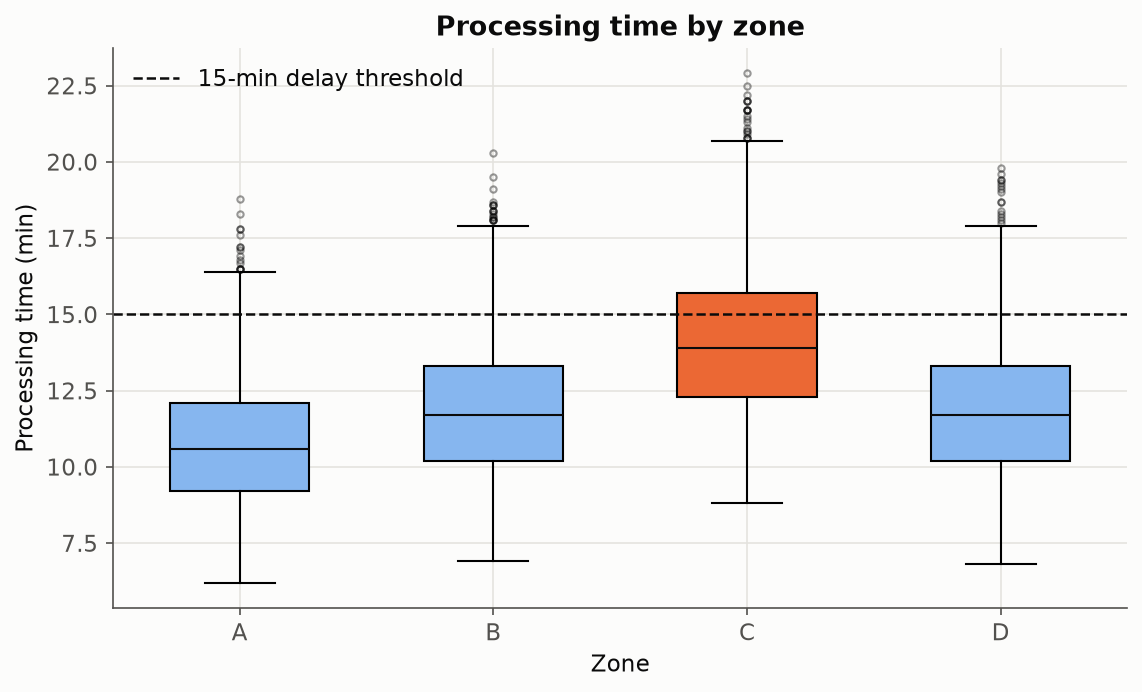

05_workload_confounding.png


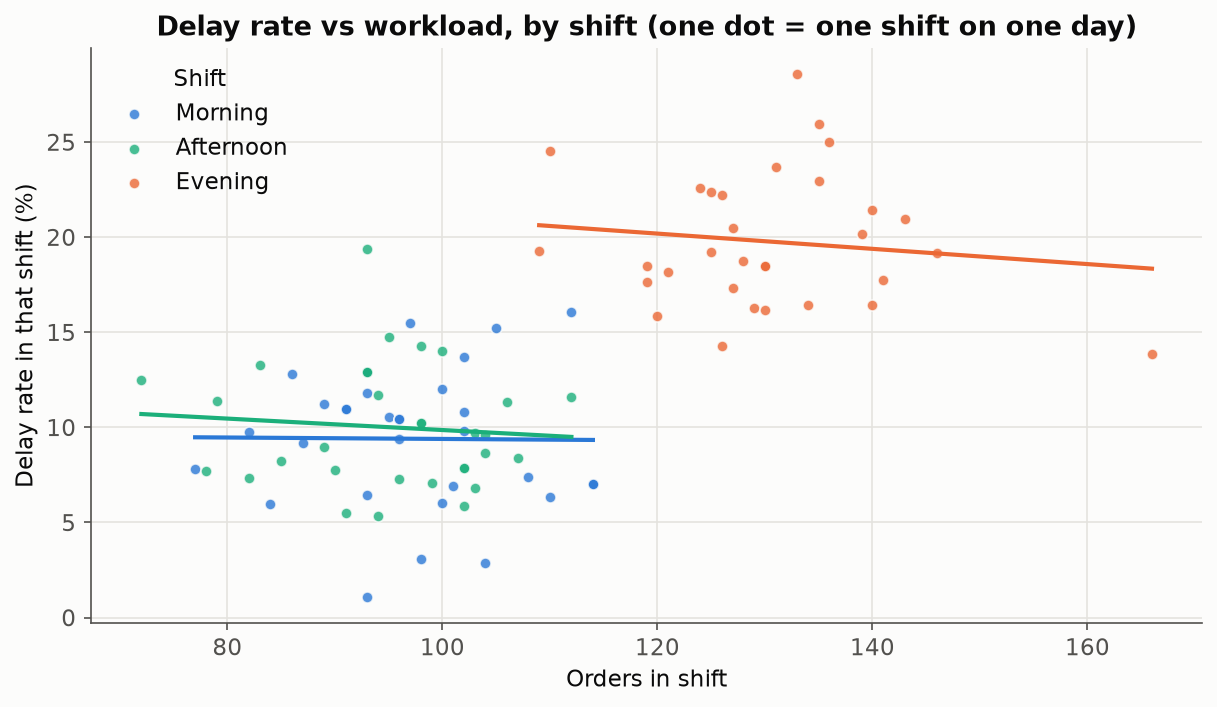

06_validation_true_vs_estimate.png


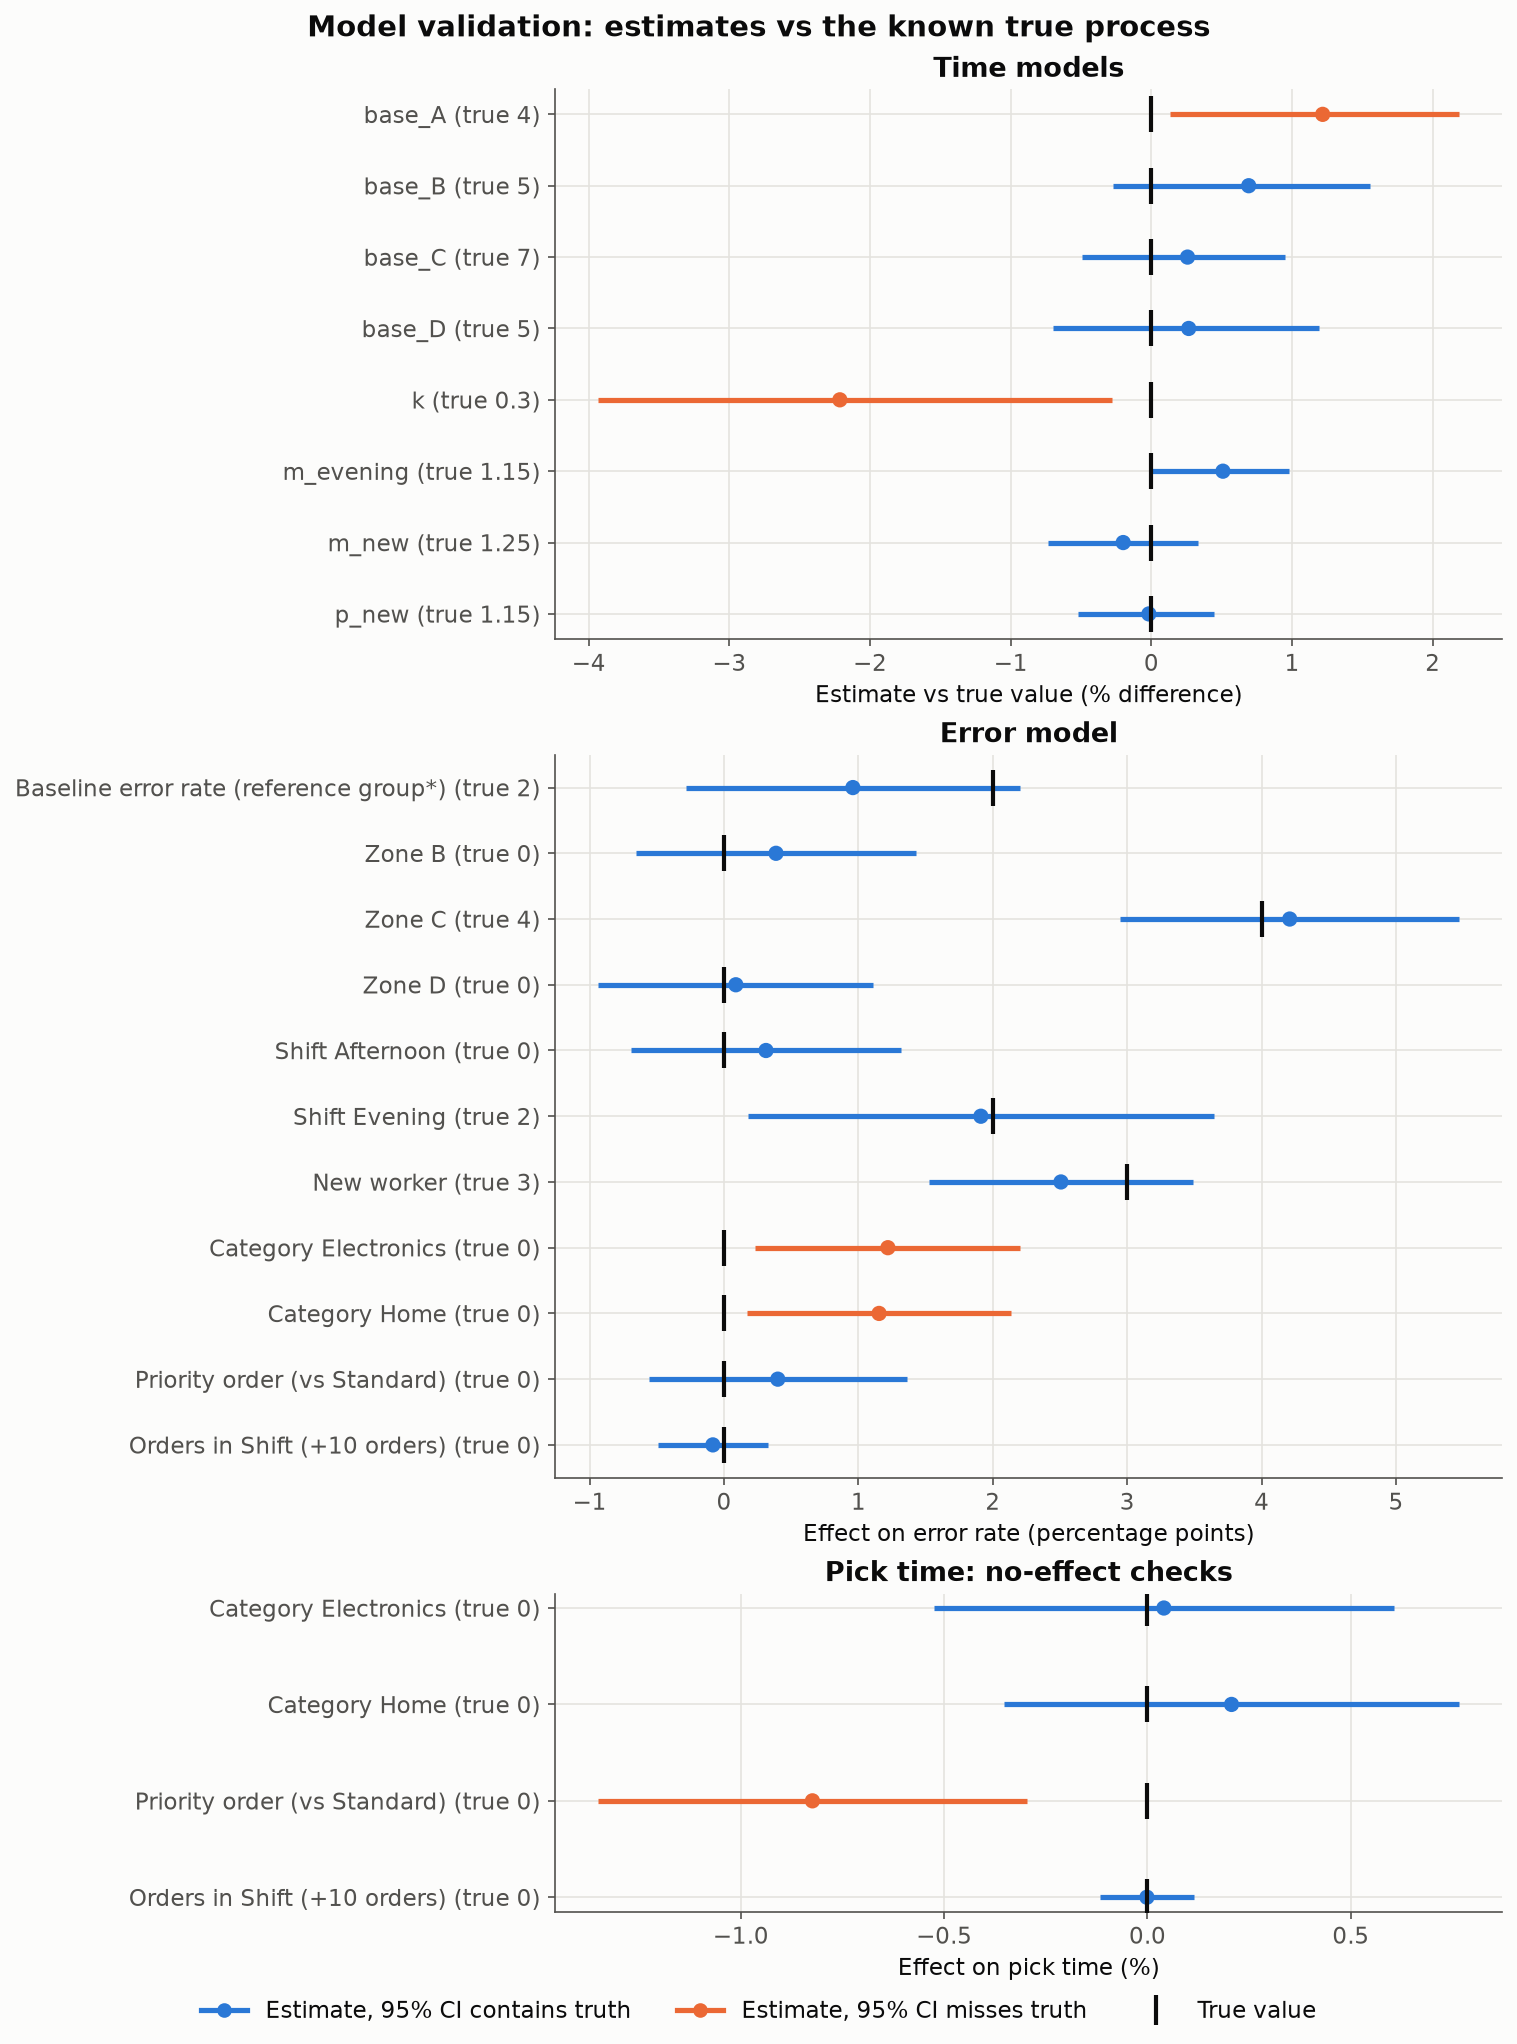

07_scenario_comparison.png


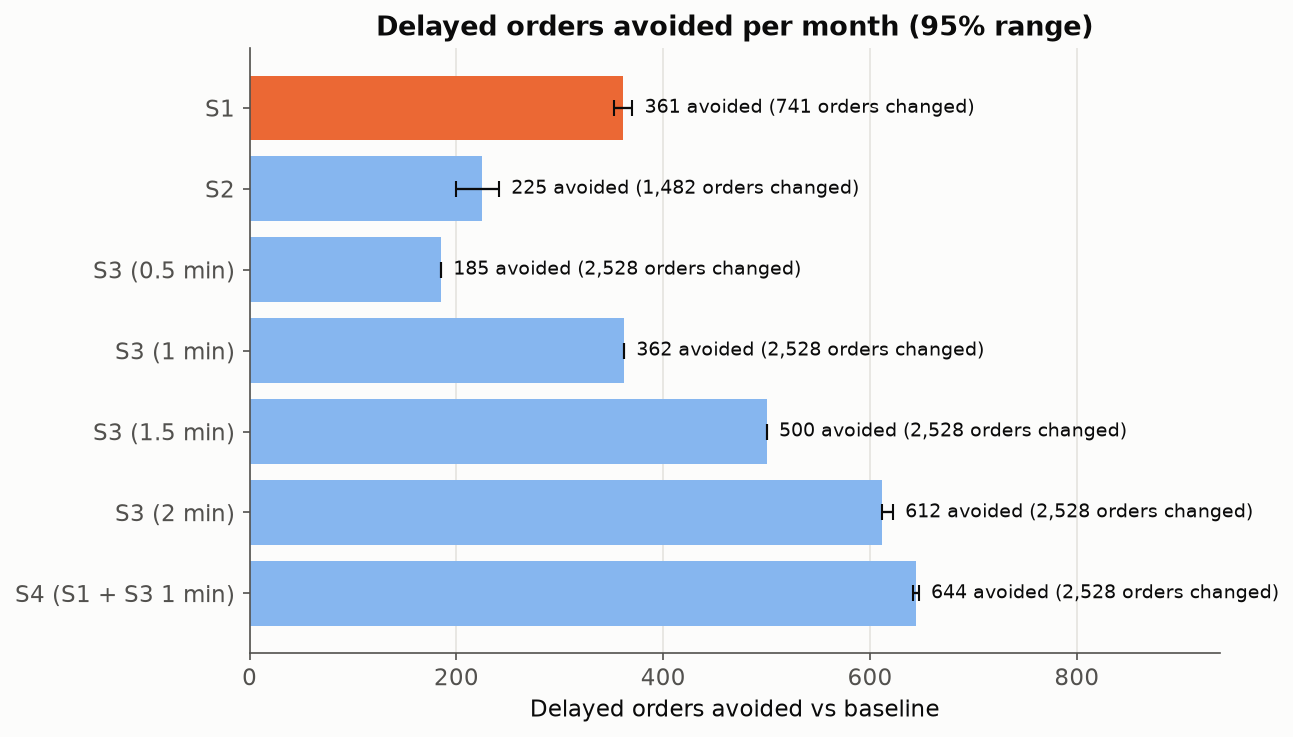

08_s3_delta_sensitivity.png


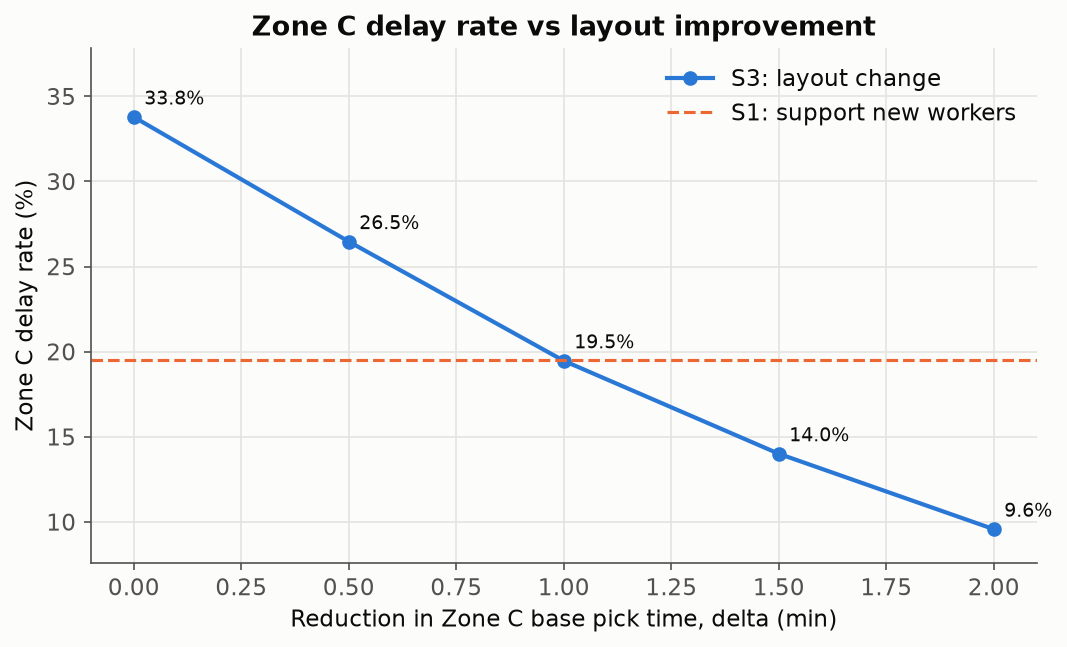

09_threshold_sensitivity.png


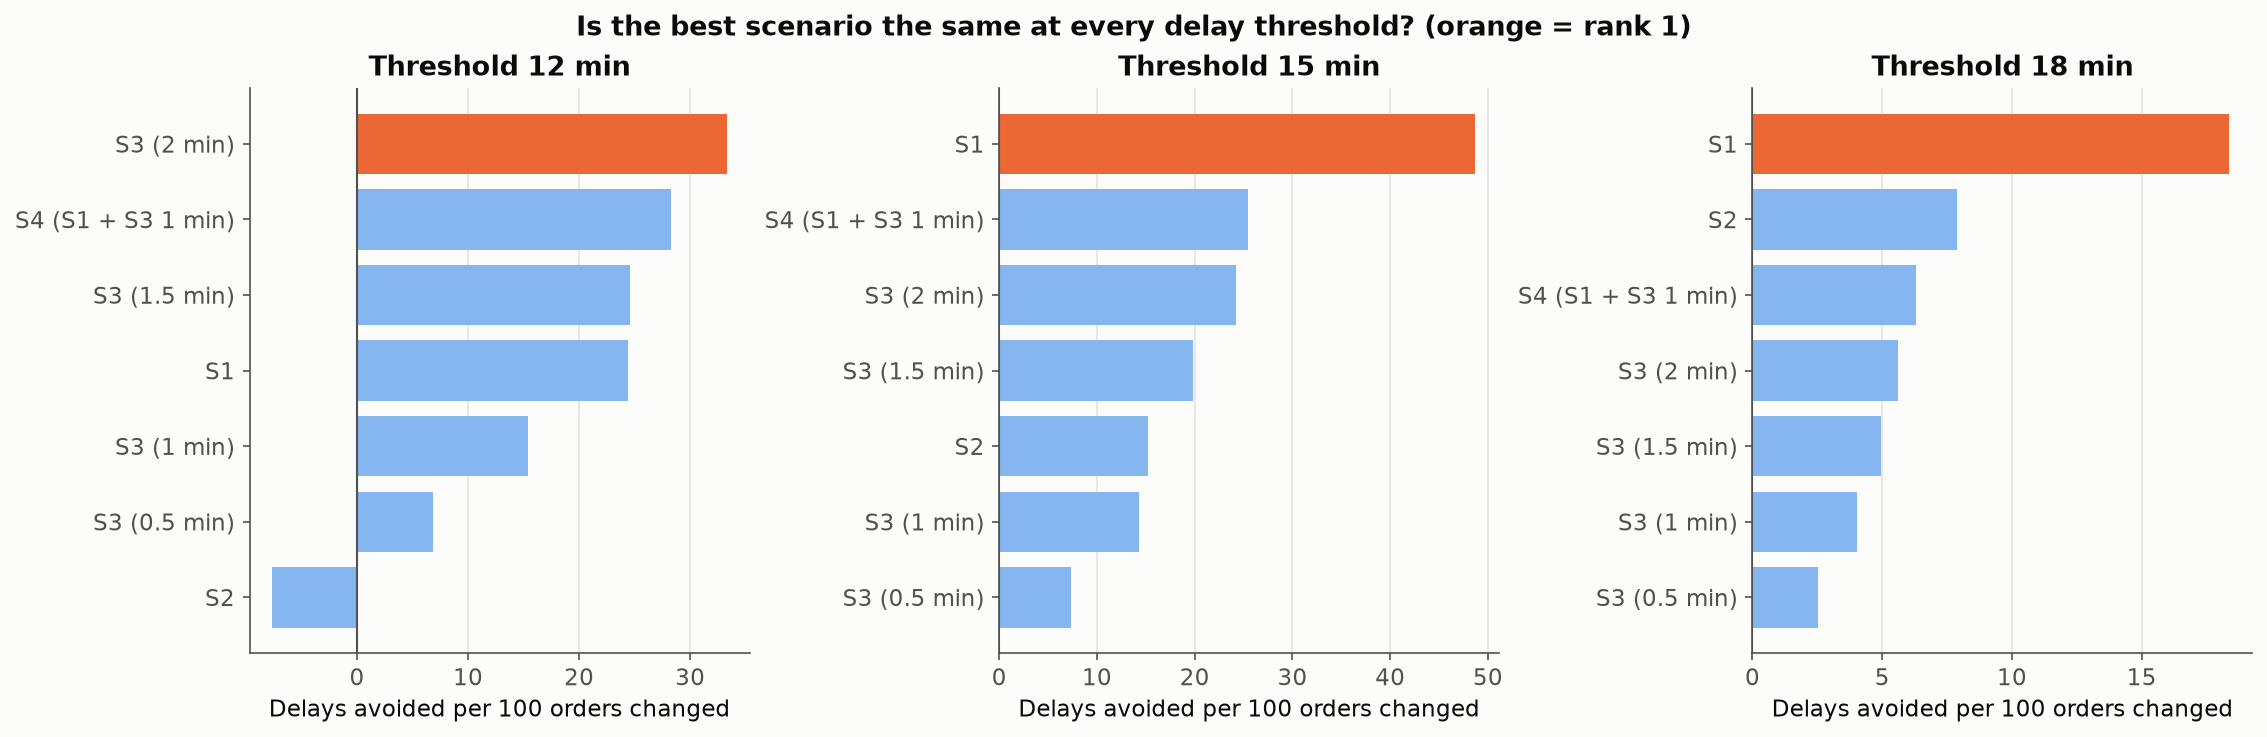

In [20]:
from IPython.display import Image, display
for path in sorted((ROOT / "outputs" / "charts").glob("*.png")):
    print(path.name)
    display(Image(filename=str(path), width=650))

## Summary

The full write-up, with every number generated from these functions, is in [`outputs/report.md`](../outputs/report.md) and the [README](../README.md).

* Delays concentrate in New workers in Zone C, although New workers are spread evenly across zones.
* The "busy shifts cause delays" pattern is confounding by the evening shift.
* The models recover the known true parameters closely, and the validation table shows honestly where they do not.
* Supporting New workers in Zone C gives the most delay reduction per order changed at the 15-minute threshold; the next step is a controlled trial.